# jobfit: how the measurement changed the system

Retrieval over 135 real job ads. The pipeline is ordinary on purpose; the
evaluation is the project.

**This notebook calls the code, it does not repeat it.** Everything comes from
`src/jobfit/` and `eval/`, the same modules the tests and CI use, so a number
here cannot disagree with a number in the repository. Nothing below is typed
in by hand.

Read it as the order things actually happened: build something, measure it,
find out the measurement is about your own code first.

In [1]:
import json
import os
import sys

sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("../src"))

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from eval import metrics  # noqa: E402
from eval.retrievers import Corpus, load_ads  # noqa: E402
from jobfit import relevance  # noqa: E402
from jobfit.chunking import chunk_all  # noqa: E402

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
GREEN, GREY, ORANGE, BLUE = "#1b6b4a", "#9aa0a6", "#c0504d", "#4a7fe0"
print("imported from the same modules CI runs")

imported from the same modules CI runs


## 1. What the corpus actually is

Live job ads from the Arbeitnow public board, no API key. A snapshot is frozen
in `data/eval_corpus.jsonl` so the numbers mean something between runs.

In [2]:
ads = load_ads()
lengths = [len(a.text) for a in ads]

print(f"ads              {len(ads)}")
print(f"companies        {len({a.company for a in ads if a.company})}")
print(f"median length    {int(np.median(lengths)):,} characters")
print(f"shortest         {min(lengths):,}")
print(f"longest          {max(lengths):,}")

ads              135
companies        77
median length    5,020 characters
shortest         1,387
longest          16,598


In [3]:
a = ads[0]
print(a.title, "|", a.company, "|", a.location)
print()
print(a.text[:420].strip(), "...")

Senior Creative Strategist – Paid Social / Online Video (m/f/d) | autoscout24 | 

A career driven by you. Join AutoScout24 Group and experience life in the fast lane. We’re not just leading the market; we’re creating it. We’re constantly innovating, evolving and transforming things for our customers. We’re driven, ambitious and determined to do our best work, together. For a career that doesn’t stand still, where you can put your ideas in the driving seat and change the way the world moves, join o ...


Note the length. A median ad is five thousand characters, most of which is not
about the job. That matters in section 3.

## 2. The filter was keeping everything

The corpus is meant to hold AI, ML and data roles. The first filter matched
keywords as substrings. Two things went wrong, and both are obvious once you
look.

In [4]:
# the substring bug, in one line
print("'llm' in 'fulfillment' ->", "llm" in "fulfillment")
print()

# The second problem: how often "AI" appears at all. Counted both ways, because
# the gap between them IS the bug. _has is the module's own whole-word matcher.
naive = sum(1 for a in ads if "ai" in a.text.lower())
word = sum(1 for a in ads if relevance._has("ai", a.text.lower()))

print(f'substring  "ai"   {naive} of {len(ads)}   also fires inside said, maintain, chair')
print(f'whole word "ai"   {word} of {len(ads)}   the real figure')

'llm' in 'fulfillment' -> True

substring  "ai"   134 of 135   also fires inside said, maintain, chair
whole word "ai"   121 of 135   the real figure


Every company selling software says AI somewhere, so the word carries almost no
information about the job. Matching it kept the corpus intact.

The replacement rests on one observation: **the title says what the job is, the
body says what the company does.** The title decides; the body is only consulted
when a title like "Senior Software Engineer" does not say.

In [5]:
with open("../eval/labels.json", encoding="utf-8") as f:
    labels = json.load(f)["labels"]
gold = {k for k, v in labels.items() if v == "yes"}   # "clearly that job"

old_keep = {a.id for a in ads}                   # the substring filter kept all of them
new_keep = {a.id for a in ads if relevance.is_relevant(a.title, a.text)}

def pr(keep):
    tp = len(keep & gold)
    return tp / max(len(keep), 1), tp / max(len(gold), 1)

for name, keep in [("substring match", old_keep), ("title decides", new_keep)]:
    p, r = pr(keep)
    print(f"{name:18s} kept {len(keep):4d}   precision {p:.2f}   recall {r:.2f}")

substring match    kept  135   precision 0.21   recall 1.00
title decides      kept   37   precision 0.76   recall 1.00


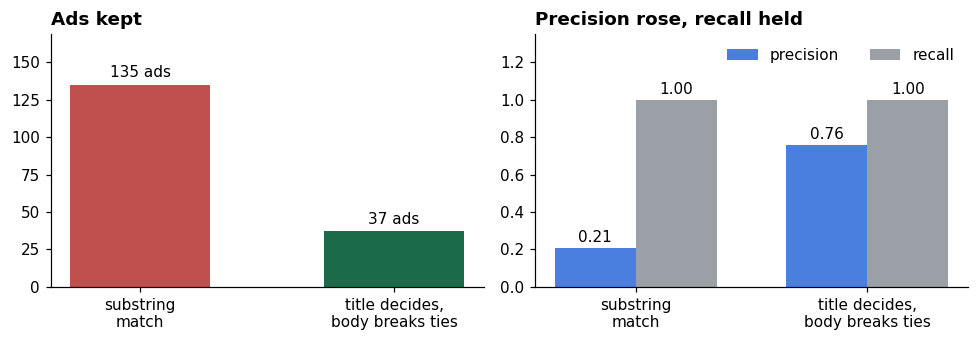

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
names = ["substring\nmatch", "title decides,\nbody breaks ties"]
kept = [len(old_keep), len(new_keep)]
prec = [pr(old_keep)[0], pr(new_keep)[0]]
rec  = [pr(old_keep)[1], pr(new_keep)[1]]

b = ax1.bar(names, kept, color=[ORANGE, GREEN], width=.55)
ax1.bar_label(b, fmt="%d ads", padding=3)
ax1.set_ylim(0, max(kept) * 1.25)
ax1.set_title("Ads kept", loc="left", fontweight="bold")

x = np.arange(2)
w = .35
b1 = ax2.bar(x - w/2, prec, w, label="precision", color=BLUE)
b2 = ax2.bar(x + w/2, rec, w, label="recall", color=GREY)
ax2.bar_label(b1, fmt="%.2f", padding=2)
ax2.bar_label(b2, fmt="%.2f", padding=2)
ax2.set_xticks(x)
ax2.set_xticklabels(names)
ax2.set_ylim(0, 1.35)
ax2.legend(frameon=False, ncol=2)
ax2.set_title("Precision rose, recall held", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

**21% to 76% precision, and recall stayed at 1.00.** The precision was not
bought by throwing away real roles, which is the failure mode worth checking.

## 3. A third of the chunks say nothing about the job

Chunks are what actually get retrieved. If a chunk is an About Us paragraph it
is a retrievable item with nothing retrievable in it.

In [7]:
chunks = chunk_all(ads)
boiler = [c for c in chunks if relevance.is_boilerplate(c.text)]
print(f"chunks               {len(chunks)}")
print(f"no requirement signal {len(boiler)}  ({100*len(boiler)/len(chunks):.0f}%)")
print()
print("an example of one:")
print(" ", boiler[0].text[:260].strip().replace("\n", " "), "...")

chunks               926
no requirement signal 315  (34%)

an example of one:
  to strengthen how we show up across channels and help evolve how the brand is expressed going forward. What You’ll Do  Develop creative concepts and write scripts, hooks and copy for paid social and YouTube ads, drawing on audience needs, brand priorities and ...


For the query *"PyTorch computer vision deep learning"* the old top result was a
chunk reading *"AI is transforming our world"*. Generic marketing prose about AI
sits closer to a generic AI query than a list of tools does. Downweighting these
was the cheapest fix tried.

## 4. Three query families, kept apart

61 queries written by hand. They are separated so an easy family cannot hide a
failure in a hard one, which is the main thing a single average will do to you.

In [8]:
with open("../eval/queries.json", encoding="utf-8") as f:
    qs = json.load(f)
for fam, note in qs["families"].items():
    examples = [q for q in qs["queries"] if q["family"] == fam]
    print(f"{fam:18s} {len(examples):2d}  {note}")
    print(f'{"":18s}     e.g. "{examples[0]["query"][:62]}"')
    print()

known_item         35  one correct ad, query is a stripped requirement line
                       e.g. "building functionality internal platforms products rather deve"

keyword_topical    18  correct answers defined by a keyword, so it favours keyword retrieval by construction
                       e.g. "pytorch"

semantic_topical    8  hand marked, little word overlap with the ads
                       e.g. "something I could do while still a student"



## 5. Seven retrievers on the same queries

Now the part the project exists for. Every variant returns ten ads and is scored
the same way.

In [9]:
from eval.retrievers import VARIANTS

corpora = {False: Corpus(filtered=False), True: Corpus(filtered=True)}
queries = qs["queries"]
fams = ["known_item", "keyword_topical", "semantic_topical"]

scores = {}
for name, (needs_filter, fn) in VARIANTS.items():
    c = corpora[needs_filter]
    per_fam = {}
    for fam in fams:
        rows = [(fn(c, q["query"], 10), set(q["gold"]))
                for q in queries if q["family"] == fam]
        per_fam[fam] = {
            "recall": np.mean([metrics.recall_at_k(r, g, 10) for r, g in rows]),
            "mrr": np.mean([metrics.reciprocal_rank(r, g) for r, g in rows]),
        }
    scores[name] = per_fam
    print(f"scored {name}")

scored dense (baseline)
scored bm25 only
scored hybrid rrf
scored hybrid + boilerplate
scored hybrid + relevance filter
scored hybrid + filter + boilerplate
scored hybrid + filter + boilerplate + rerank


In [10]:
hdr = f'{"variant":40s}' + "".join(f'{f.split("_")[0]:>12s}' for f in fams)
print(hdr)
print("-" * len(hdr))
for name, per_fam in scores.items():
    row = f"{name:40s}" + "".join(f'{per_fam[f]["recall"]:12.3f}' for f in fams)
    print(row)
print("\nrecall@10 by query family")

variant                                        known     keyword    semantic
----------------------------------------------------------------------------
dense (baseline)                               0.686       0.552       0.297
bm25 only                                      1.000       0.946       0.203
hybrid rrf                                     0.771       0.885       0.312
hybrid + boilerplate                           0.800       0.890       0.391
hybrid + relevance filter                      0.886       0.953       0.469
hybrid + filter + boilerplate                  0.886       0.953       0.500
hybrid + filter + boilerplate + rerank         0.914       0.972       0.547

recall@10 by query family


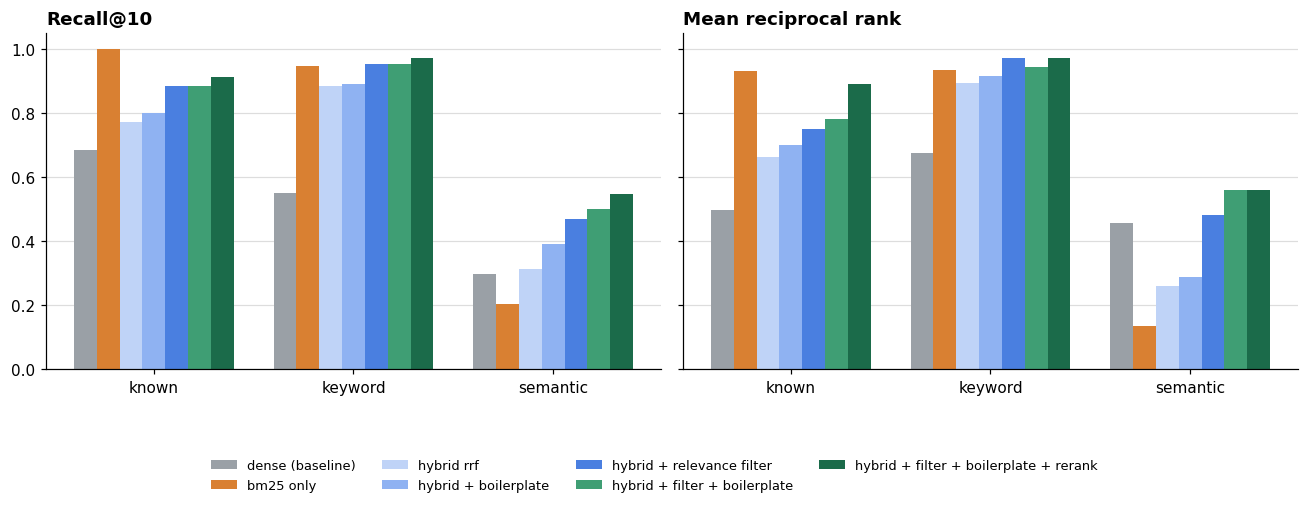

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colours = [GREY, "#d98032", "#bfd3f7", "#8fb2f2", "#4a7fe0", "#3f9e74", GREEN]

for ax, metric, title in zip(axes, ["recall", "mrr"],
                             ["Recall@10", "Mean reciprocal rank"]):
    n = len(scores)
    w = .8 / n
    for i, (name, per_fam) in enumerate(scores.items()):
        vals = [per_fam[f][metric] for f in fams]
        ax.bar([j - .4 + w/2 + i*w for j in range(3)], vals, w,
               label=name if metric == "recall" else None, color=colours[i])
    ax.set_xticks(range(3))
    ax.set_xticklabels([f.split("_")[0] for f in fams])
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylim(0, 1.05)
    ax.yaxis.grid(True, color="#dddddd", lw=.8)
    ax.set_axisbelow(True)

fig.legend(loc="lower center", ncol=4, frameon=False, fontsize=8.5,
           bbox_to_anchor=(.5, -.22))
plt.tight_layout()
plt.show()

**BM25 wins the keyword family by construction**, because those answers are
defined by a keyword. That family is a floor, not a verdict.

**BM25 also wins the known-item family outright**, which is not by construction.
For finding one specific ad in a corpus this small, forty lines of BM25 beat a
transformer. That went in the README because a finding I did not want is still a
finding.

**The semantic family is what justifies the embeddings.** Those queries share
almost no words with the ads.

## 6. The reranker, and the half of it that did not work

A cross-encoder reads query and chunk together instead of comparing vectors
embedded months apart. Too slow for 926 chunks, so it reorders the top 40.

In [12]:
base = scores["hybrid + filter + boilerplate"]
rr = scores["hybrid + filter + boilerplate + rerank"]

print(f'{"":20s}{"hybrid":>10s}{"+rerank":>10s}{"change":>10s}')
for fam in fams:
    for m in ["recall", "mrr"]:
        b, a = base[fam][m], rr[fam][m]
        flag = "   <-- did not move" if abs(a - b) < .005 else ""
        print(f'{fam.split("_")[0] + " " + m:20s}{b:10.3f}{a:10.3f}{a-b:+10.3f}{flag}')

                        hybrid   +rerank    change
known recall             0.886     0.914    +0.029
known mrr                0.783     0.893    +0.110
keyword recall           0.953     0.972    +0.019
keyword mrr              0.944     0.972    +0.028
semantic recall          0.500     0.547    +0.047
semantic mrr             0.560     0.561    +0.001   <-- did not move


**The known-item MRR gain is the real result.** A reranker reorders rather than
retrieves, so the metric about *where* the answer lands should move more than the
one about whether it appears. It does.

**The semantic MRR did not move at all.** Recall rose, so the reranker is pulling
more correct semantic answers into the top ten and ranking none of them higher.
Those are exactly the queries a cross-encoder was supposed to help most with. It
went against the reason for adding it, so it stays in the table and in the open
questions.

## 7. The bug that only appeared on somebody else's machine

CI regenerates `eval/results.md` on every push and fails if it differs. It went
red on a commit that touched nothing it runs.

In [13]:
c = corpora[False]
differ = 0
for q in queries:
    s = c.vectors @ c.query_vector(q["query"])
    quick = np.argsort(-s)[:80]                  # numpy's default: quicksort
    stable = np.argsort(-s, kind="stable")[:80]
    differ += not np.array_equal(quick, stable)

tied = sum(len(np.unique(np.round(c.vectors @ c.query_vector(q["query"]), 6)))
           < len(c.chunks) for q in queries[:10])

print(f"queries where the sort algorithm changes the top 80   {differ} of {len(queries)}")
print(f"queries with tied scores (first 10 checked)           {tied} of 10")

queries where the sort algorithm changes the top 80   21 of 61
queries with tied scores (first 10 checked)           10 of 10


`np.argsort` defaults to quicksort, which is **not stable**. Every query here has
tied scores, so the order of tied results is a property of the numpy build and
the platform. The published table reproduced on the machine that wrote it and
not on a Linux runner.

The fix is `kind="stable"` on every ranking derived from a score. **The numbers
did not move.** They were right, they just were not reproducible, and a
reproducibility harness that only reproduces in one place is not one.

BM25 was already safe, because Python's `sorted` is stable.

## What this does not do

No answer generation, no faithfulness scoring of a generated answer against its
citations, and not deployed yet.

135 ads is a small corpus, and some of the conclusions here, particularly BM25
beating the embeddings on known-item retrieval, would probably not survive at a
hundred thousand. There is one annotator, me, so there is no inter-annotator
agreement figure. The semantic family is eight queries, which is the family that
matters most and the one with the widest error bars.

All of which is in the README too. The point of measuring it was never to make
the numbers look good.